# Zambia's staple food prices, December 2022 to October 2026

**Question:** Did Zambia's staple food prices recover after the 2024 drought, and who still pays the most?

*Rewrite the question and the short intro below in your own words.*

Mealie meal and maize are the foundation of most Zambian meals, so their prices affect almost every household. This notebook follows three staples, breakfast mealie meal, roller mealie meal and maize grain, across four years using official ZamStats data.

## 1. The data

The data is built into this notebook, so there is nothing to upload. Just run the cells from top to bottom.

The first code cell holds the prices taken from 10 ZamStats Monthly Bulletins. The second loads them and sets up the chart style.

In [1]:
from io import StringIO

# National average prices, Dec 2022 to Oct 2026 (ZamStats Monthly Bulletins, Table 7)
NATIONAL_CSV = """month,product,unit,price_kwacha,real_price_oct2026_kwacha,bulletins_confirming,sources
2022-12,Breakfast mealie meal,25 kg bag,171.72,262.33,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-01,Breakfast mealie meal,25 kg bag,181.46,271.59,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-02,Breakfast mealie meal,25 kg bag,196.84,288.98,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-03,Breakfast mealie meal,25 kg bag,193.0,280.41,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-04,Breakfast mealie meal,25 kg bag,202.87,292.04,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-05,Breakfast mealie meal,25 kg bag,201.72,288.68,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-06,Breakfast mealie meal,25 kg bag,204.06,289.7,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7"
2023-07,Breakfast mealie meal,25 kg bag,226.37,318.54,2,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2023-08,Breakfast mealie meal,25 kg bag,246.55,344.19,3,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2023-09,Breakfast mealie meal,25 kg bag,269.73,374.08,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2023-10,Breakfast mealie meal,25 kg bag,288.46,397.03,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2023-11,Breakfast mealie meal,25 kg bag,288.94,394.07,4,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2023-12,Breakfast mealie meal,25 kg bag,286.31,386.71,3,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2024-01,Breakfast mealie meal,25 kg bag,292.09,386.29,2,"ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-02,Breakfast mealie meal,25 kg bag,310.97,402.25,2,"ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-03,Breakfast mealie meal,25 kg bag,322.37,411.79,3,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-04,Breakfast mealie meal,25 kg bag,325.56,411.8,4,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-05,Breakfast mealie meal,25 kg bag,328.84,410.3,4,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-06,Breakfast mealie meal,25 kg bag,331.23,408.06,2,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2024-07,Breakfast mealie meal,25 kg bag,334.48,407.97,3,"ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 268 (Jul 2025), Table 7"
2024-08,Breakfast mealie meal,25 kg bag,333.28,403.0,1,"ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2024-09,Breakfast mealie meal,25 kg bag,334.11,400.87,1,"ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-10,Breakfast mealie meal,25 kg bag,341.11,405.86,2,"ZamStats Monthly Vol 259 (Oct 2024), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2024-11,Breakfast mealie meal,25 kg bag,338.7,396.64,1,"ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2024-12,Breakfast mealie meal,25 kg bag,342.16,395.85,1,"ZamStats Monthly Vol 268 (Jul 2025), Table 7"
2025-01,Breakfast mealie meal,25 kg bag,356.52,404.08,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-02,Breakfast mealie meal,25 kg bag,360.45,399.08,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-03,Breakfast mealie meal,25 kg bag,364.37,399.38,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2025-04,Breakfast mealie meal,25 kg bag,358.86,389.6,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-05,Breakfast mealie meal,25 kg bag,344.41,372.67,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-06,Breakfast mealie meal,25 kg bag,307.78,332.39,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-07,Breakfast mealie meal,25 kg bag,275.39,297.14,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-08,Breakfast mealie meal,25 kg bag,260.59,279.75,3,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-09,Breakfast mealie meal,25 kg bag,260.34,278.1,3,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-10,Breakfast mealie meal,25 kg bag,262.56,279.23,4,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2025-11,Breakfast mealie meal,25 kg bag,273.26,288.61,3,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2025-12,Breakfast mealie meal,25 kg bag,286.7,298.3,2,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-01,Breakfast mealie meal,25 kg bag,300.15,310.85,3,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-02,Breakfast mealie meal,25 kg bag,302.21,311.24,2,"ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-03,Breakfast mealie meal,25 kg bag,300.98,308.13,1,"ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-04,Breakfast mealie meal,25 kg bag,296.1,301.13,1,"ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-05,Breakfast mealie meal,25 kg bag,289.12,293.47,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-06,Breakfast mealie meal,25 kg bag,272.66,276.58,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-07,Breakfast mealie meal,25 kg bag,252.13,255.37,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-08,Breakfast mealie meal,25 kg bag,243.96,246.54,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-09,Breakfast mealie meal,25 kg bag,236.34,237.98,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-10,Breakfast mealie meal,25 kg bag,235.86,235.86,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2022-12,Maize grain,20 litre tin,87.75,134.05,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-01,Maize grain,20 litre tin,93.44,139.85,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-02,Maize grain,20 litre tin,97.78,143.55,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-03,Maize grain,20 litre tin,108.6,157.79,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-04,Maize grain,20 litre tin,109.84,158.12,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-05,Maize grain,20 litre tin,101.16,144.77,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-06,Maize grain,20 litre tin,99.1,140.69,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7"
2023-07,Maize grain,20 litre tin,105.15,147.96,2,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2023-08,Maize grain,20 litre tin,108.66,151.69,3,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2023-09,Maize grain,20 litre tin,120.28,166.81,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2023-10,Maize grain,20 litre tin,134.83,185.58,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2023-11,Maize grain,20 litre tin,138.13,188.39,4,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2023-12,Maize grain,20 litre tin,145.99,197.18,3,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2024-01,Maize grain,20 litre tin,159.84,211.39,2,"ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-02,Maize grain,20 litre tin,172.82,223.55,2,"ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-03,Maize grain,20 litre tin,186.15,237.79,3,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-04,Maize grain,20 litre tin,180.98,228.92,4,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-05,Maize grain,20 litre tin,179.16,223.54,4,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-06,Maize grain,20 litre tin,171.56,211.36,2,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2024-07,Maize grain,20 litre tin,176.2,214.91,3,"ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 268 (Jul 2025), Table 7"
2024-08,Maize grain,20 litre tin,168.86,204.18,1,"ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2024-09,Maize grain,20 litre tin,168.31,201.94,1,"ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-10,Maize grain,20 litre tin,170.94,203.39,2,"ZamStats Monthly Vol 259 (Oct 2024), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2024-11,Maize grain,20 litre tin,174.33,204.15,1,"ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2024-12,Maize grain,20 litre tin,185.45,214.55,1,"ZamStats Monthly Vol 268 (Jul 2025), Table 7"
2025-01,Maize grain,20 litre tin,191.91,217.51,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-02,Maize grain,20 litre tin,228.76,253.27,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-03,Maize grain,20 litre tin,211.29,231.59,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2025-04,Maize grain,20 litre tin,182.93,198.6,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-05,Maize grain,20 litre tin,142.1,153.76,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-06,Maize grain,20 litre tin,119.25,128.79,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-07,Maize grain,20 litre tin,113.86,122.85,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-08,Maize grain,20 litre tin,111.59,119.79,3,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-09,Maize grain,20 litre tin,119.66,127.82,3,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-10,Maize grain,20 litre tin,121.38,129.09,4,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2025-11,Maize grain,20 litre tin,129.66,136.94,3,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2025-12,Maize grain,20 litre tin,138.85,144.47,2,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-01,Maize grain,20 litre tin,145.96,151.16,3,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-02,Maize grain,20 litre tin,158.44,163.18,2,"ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-03,Maize grain,20 litre tin,157.82,161.57,1,"ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-04,Maize grain,20 litre tin,149.94,152.49,1,"ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-05,Maize grain,20 litre tin,126.66,128.56,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-06,Maize grain,20 litre tin,110.8,112.39,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-07,Maize grain,20 litre tin,99.83,101.11,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-08,Maize grain,20 litre tin,97.38,98.41,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-09,Maize grain,20 litre tin,101.67,102.38,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-10,Maize grain,20 litre tin,106.98,106.98,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2022-12,Roller mealie meal,25 kg bag,138.85,212.11,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-01,Roller mealie meal,25 kg bag,148.19,221.79,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-02,Roller mealie meal,25 kg bag,162.78,238.97,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-03,Roller mealie meal,25 kg bag,160.21,232.77,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-04,Roller mealie meal,25 kg bag,166.82,240.15,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-05,Roller mealie meal,25 kg bag,163.66,234.21,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2023-06,Roller mealie meal,25 kg bag,165.59,235.08,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7"
2023-07,Roller mealie meal,25 kg bag,184.8,260.04,2,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2023-08,Roller mealie meal,25 kg bag,204.35,285.28,3,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2023-09,Roller mealie meal,25 kg bag,224.84,311.82,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2023-10,Roller mealie meal,25 kg bag,238.29,327.98,2,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2023-11,Roller mealie meal,25 kg bag,240.14,327.51,4,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2023-12,Roller mealie meal,25 kg bag,239.53,323.53,3,"ZamStats Monthly Vol 249 (Dec 2023), Table 10; ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2024-01,Roller mealie meal,25 kg bag,244.44,323.27,2,"ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-02,Roller mealie meal,25 kg bag,263.44,340.77,2,"ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-03,Roller mealie meal,25 kg bag,273.91,349.89,3,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-04,Roller mealie meal,25 kg bag,278.97,352.87,4,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-05,Roller mealie meal,25 kg bag,281.47,351.2,4,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-06,Roller mealie meal,25 kg bag,284.35,350.31,2,"ZamStats Monthly Vol 255 (Jun 2024), Table 7; ZamStats Monthly Vol 256 (Jul 2024), Table 7"
2024-07,Roller mealie meal,25 kg bag,289.82,353.5,3,"ZamStats Monthly Vol 256 (Jul 2024), Table 7; ZamStats Monthly Vol 257 (Aug 2024), Table 7; ZamStats Monthly Vol 268 (Jul 2025), Table 7"
2024-08,Roller mealie meal,25 kg bag,290.98,351.85,1,"ZamStats Monthly Vol 257 (Aug 2024), Table 7"
2024-09,Roller mealie meal,25 kg bag,291.49,349.73,1,"ZamStats Monthly Vol 259 (Oct 2024), Table 7"
2024-10,Roller mealie meal,25 kg bag,293.22,348.88,2,"ZamStats Monthly Vol 259 (Oct 2024), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2024-11,Roller mealie meal,25 kg bag,291.84,341.77,1,"ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2024-12,Roller mealie meal,25 kg bag,293.47,339.52,1,"ZamStats Monthly Vol 268 (Jul 2025), Table 7"
2025-01,Roller mealie meal,25 kg bag,306.52,347.41,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-02,Roller mealie meal,25 kg bag,307.06,339.97,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-03,Roller mealie meal,25 kg bag,306.36,335.79,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7"
2025-04,Roller mealie meal,25 kg bag,294.19,319.39,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-05,Roller mealie meal,25 kg bag,285.24,308.64,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-06,Roller mealie meal,25 kg bag,259.04,279.76,3,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-07,Roller mealie meal,25 kg bag,222.02,239.56,2,"ZamStats Monthly Vol 268 (Jul 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7"
2025-08,Roller mealie meal,25 kg bag,202.74,217.65,3,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-09,Roller mealie meal,25 kg bag,203.52,217.4,3,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2025-10,Roller mealie meal,25 kg bag,206.36,219.46,4,"ZamStats Monthly Vol 271 (Oct 2025), Table 7; ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2025-11,Roller mealie meal,25 kg bag,216.08,228.22,3,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2025-12,Roller mealie meal,25 kg bag,225.97,235.11,2,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-01,Roller mealie meal,25 kg bag,239.64,248.18,3,"ZamStats Monthly Vol 274 (Jan 2026), Table 7; ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-02,Roller mealie meal,25 kg bag,247.56,254.96,2,"ZamStats Monthly Vol 277 (Apr 2026), Table 7; ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-03,Roller mealie meal,25 kg bag,246.21,252.06,1,"ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-04,Roller mealie meal,25 kg bag,245.97,250.15,1,"ZamStats Monthly Vol 277 (Apr 2026), Table 7"
2026-05,Roller mealie meal,25 kg bag,236.4,239.95,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-06,Roller mealie meal,25 kg bag,222.19,225.38,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-07,Roller mealie meal,25 kg bag,202.28,204.88,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-08,Roller mealie meal,25 kg bag,192.11,194.14,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-09,Roller mealie meal,25 kg bag,182.19,183.45,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
2026-10,Roller mealie meal,25 kg bag,181.99,181.99,1,"ZamStats Monthly Vol 283 (Oct 2026), Table 7"
"""

# Cheapest and most expensive districts, 10 snapshots (ZamStats Monthly Bulletins, Table 6)
DISTRICT_CSV = """month,product,unit,min_price_kwacha,cheapest_district,max_price_kwacha,most_expensive_district,gap_ratio,note,source
2023-12,Breakfast mealie meal,25 kg bag,230.0,Monze,350,Nakonde,1.52,,"ZamStats Monthly (Vol 249), Table 6"
2024-06,Breakfast mealie meal,25 kg bag,230.0,Chibombo,400,Chiengi,1.74,,"ZamStats Monthly (Vol 255), Table 6"
2024-07,Breakfast mealie meal,25 kg bag,230.0,Chibombo,400,Chilubi,1.74,,"ZamStats Monthly (Vol 256), Table 6"
2024-08,Breakfast mealie meal,25 kg bag,230.0,"Mpulungu, Kalabo",400,"Chienge, Chilubi",1.74,,"ZamStats Monthly (Vol 257), Table 6"
2024-10,Breakfast mealie meal,25 kg bag,250.0,Mpika,400,Chiengi,1.6,,"ZamStats Monthly Oct 2024 (Vol 259), Table 6"
2025-07,Breakfast mealie meal,25 kg bag,190.0,Lusaka,400,Chilubi,2.11,,"ZamStats Monthly (Vol 268), Table 6"
2025-10,Breakfast mealie meal,25 kg bag,200.0,Kitwe,380,Chiengi,1.9,,"ZamStats Monthly Oct 2025 (Vol 271), Table 6"
2026-01,Breakfast mealie meal,25 kg bag,268.5,Lusaka,420,Chilubi,1.56,"Minimum printed as ""268.5.00"" in the bulletin; read as 268.50, verify","ZamStats Monthly (Vol 274), Table 6"
2026-04,Breakfast mealie meal,25 kg bag,235.0,Kabwe,400,Chilubi,1.7,,"ZamStats Monthly (Vol 277), Table 6"
2026-10,Breakfast mealie meal,25 kg bag,180.0,Mkushi,390,Chilubi,2.17,,"ZamStats Monthly Oct 2026 (Vol 283), Table 6"
2023-12,Maize grain,20 litre tin,90.0,Monze,200,Kaputa,2.22,,"ZamStats Monthly (Vol 249), Table 6"
2024-06,Maize grain,20 litre tin,100.0,Mungwi,240,Shangombo,2.4,,"ZamStats Monthly (Vol 255), Table 6"
2024-07,Maize grain,20 litre tin,100.0,Mungwi,240,Kazungula,2.4,,"ZamStats Monthly (Vol 256), Table 6"
2024-08,Maize grain,20 litre tin,100.0,"Mfuwe, Isoka",260,Zambezi,2.6,,"ZamStats Monthly (Vol 257), Table 6"
2024-10,Maize grain,20 litre tin,100.0,Mafinga,240,Zambezi,2.4,,"ZamStats Monthly Oct 2024 (Vol 259), Table 6"
2025-07,Maize grain,20 litre tin,80.0,Chibombo,200,Kazungula,2.5,,"ZamStats Monthly (Vol 268), Table 6"
2025-10,Maize grain,20 litre tin,80.0,"Mbala, Lukulu, Mazabuka, Mongu",210,Mambwe,2.62,,"ZamStats Monthly Oct 2025 (Vol 271), Table 6"
2026-01,Maize grain,20 litre tin,90.0,Kasempa,240,Mambwe,2.67,,"ZamStats Monthly (Vol 274), Table 6"
2026-04,Maize grain,20 litre tin,100.0,Katete,240,Chilubi,2.4,,"ZamStats Monthly (Vol 277), Table 6"
2026-10,Maize grain,20 litre tin,60.0,Kasempa,160,Lusaka,2.67,,"ZamStats Monthly Oct 2026 (Vol 283), Table 6"
2023-12,Roller mealie meal,25 kg bag,190.0,Monze,300,Lukulu,1.58,,"ZamStats Monthly (Vol 249), Table 6"
2024-06,Roller mealie meal,25 kg bag,195.0,Mkushi,370,Chilubi,1.9,,"ZamStats Monthly (Vol 255), Table 6"
2024-07,Roller mealie meal,25 kg bag,195.0,Chisamba,385,Chilubi,1.97,,"ZamStats Monthly (Vol 256), Table 6"
2024-08,Roller mealie meal,25 kg bag,190.0,Kalabo,360,Shangombo,1.89,,"ZamStats Monthly (Vol 257), Table 6"
2024-10,Roller mealie meal,25 kg bag,230.0,Kasama,395,Shangombo,1.72,,"ZamStats Monthly Oct 2024 (Vol 259), Table 6"
2025-07,Roller mealie meal,25 kg bag,160.0,Lusaka,355,Kaoma,2.22,,"ZamStats Monthly (Vol 268), Table 6"
2025-10,Roller mealie meal,25 kg bag,150.0,Mwense,300,Mushindano,2.0,,"ZamStats Monthly Oct 2025 (Vol 271), Table 6"
2026-01,Roller mealie meal,25 kg bag,165.0,Kabwe,380,Chilubi,2.3,,"ZamStats Monthly (Vol 274), Table 6"
2026-04,Roller mealie meal,25 kg bag,165.0,Kabwe,360,Chilubi,2.18,,"ZamStats Monthly (Vol 277), Table 6"
2026-10,Roller mealie meal,25 kg bag,130.0,Kabwe,245,Lukulu,1.88,,"ZamStats Monthly Oct 2026 (Vol 283), Table 6"
"""

print("Data is ready.")

Data is ready.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# One consistent look for every chart
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 11, "axes.titleweight": "bold",
})
COLORS = {"Breakfast mealie meal": "#287A59", "Roller mealie meal": "#C2410C", "Maize grain": "#202522"}
PRODUCTS = list(COLORS)

df = pd.read_csv(StringIO(NATIONAL_CSV), parse_dates=["month"])
districts = pd.read_csv(StringIO(DISTRICT_CSV), parse_dates=["month"])

print("Months:", df["month"].min().date(), "to", df["month"].max().date(), "|", df["month"].nunique(), "months")
print("Products:", ", ".join(df["product"].unique()))
df.head()

Months: 2022-12-01 to 2026-10-01 | 47 months
Products: Breakfast mealie meal, Maize grain, Roller mealie meal


,month,product,unit,price_kwacha,real_price_oct2026_kwacha,bulletins_confirming,sources
0,2022-12-01,Breakfast mealie meal,25 kg bag,171.72,262.33,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
1,2023-01-01,Breakfast mealie meal,25 kg bag,181.46,271.59,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
2,2023-02-01,Breakfast mealie meal,25 kg bag,196.84,288.98,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
3,2023-03-01,Breakfast mealie meal,25 kg bag,193.00,280.41,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"
4,2023-04-01,Breakfast mealie meal,25 kg bag,202.87,292.04,1,"ZamStats Monthly Vol 249 (Dec 2023), Table 10"


## 2. Four years of prices

The price people actually paid each month, as published by ZamStats. The dot marks each product's highest price.

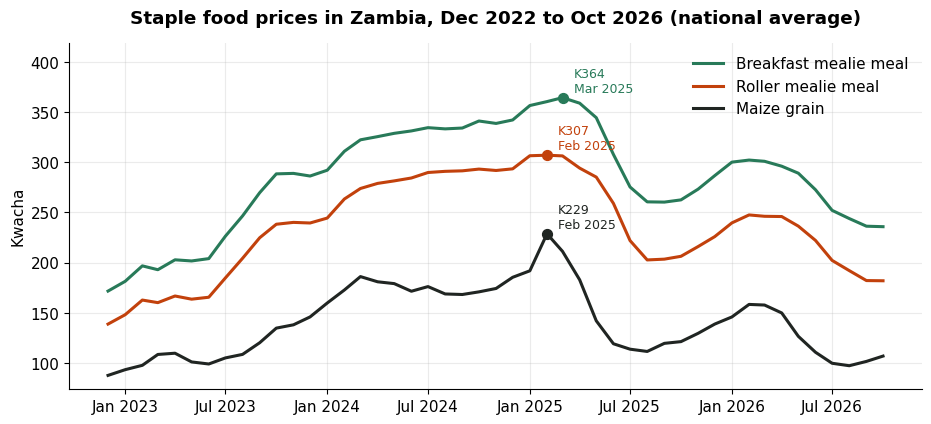

,first,peak,latest,change_from_peak_%
product,,,,
Breakfast mealie meal,171.72,364.37,235.86,-35.3
Maize grain,87.75,228.76,106.98,-53.2
Roller mealie meal,138.85,307.06,181.99,-40.7


In [3]:
fig, ax = plt.subplots()
for p in PRODUCTS:
    s = df[df["product"] == p].sort_values("month")
    ax.plot(s["month"], s["price_kwacha"], color=COLORS[p], lw=2.2, label=p)
    peak = s.loc[s["price_kwacha"].idxmax()]
    ax.scatter(peak["month"], peak["price_kwacha"], color=COLORS[p], s=50, zorder=3)
    ax.annotate(f"K{peak['price_kwacha']:.0f}\n{peak['month']:%b %Y}", (peak["month"], peak["price_kwacha"]),
                textcoords="offset points", xytext=(8, 4), fontsize=9, color=COLORS[p])
ax.set_title("Staple food prices in Zambia, Dec 2022 to Oct 2026 (national average)", pad=14)
ax.set_ylim(top=df["price_kwacha"].max() * 1.15)
ax.set_ylabel("Kwacha")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(frameon=False)
plt.show()

summary = (df.sort_values("month").groupby("product")
             .agg(first=("price_kwacha", "first"), peak=("price_kwacha", "max"), latest=("price_kwacha", "last")))
summary["change_from_peak_%"] = ((summary["latest"] / summary["peak"] - 1) * 100).round(1)
summary

**What I see:** All three staples climbed steadily from late 2022 and peaked in early 2025: breakfast mealie meal reached **K364 in March 2025**, roller mealie meal **K307** and maize grain **K229** in February 2025. Prices then fell sharply after the 2025 harvest. By October 2026, breakfast mealie meal was about **35% below its peak**, and maize grain more than **50% below**.

## 3. Price paid vs. real cost

A price of K300 in 2023 and K300 in 2026 are not the same, because everything else became more expensive too. The **real price** converts every month into October 2026 Kwacha using ZamStats' Consumer Price Index, so the months can be compared fairly.

*Real prices are a calculation, not a figure published by ZamStats.*

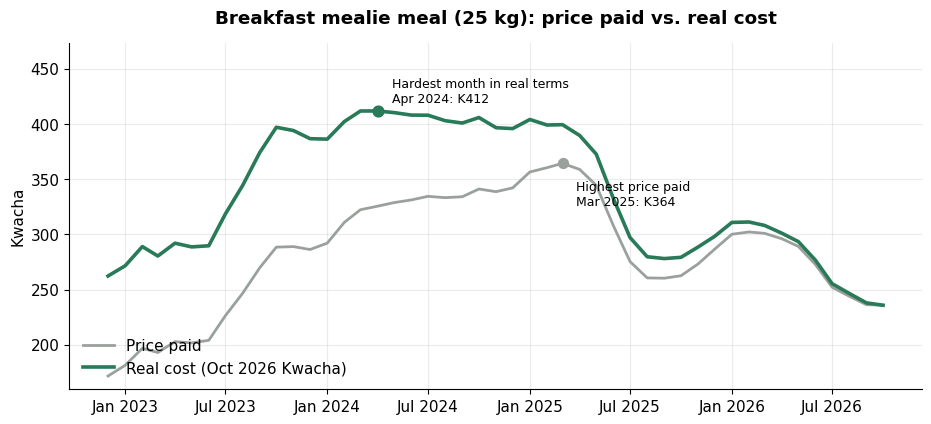

,real cost Dec 2022,hardest month (real),real cost Oct 2026,"Oct 2026 vs Dec 2022 (real, %)"
product,,,,
Breakfast mealie meal,262.33,Apr 2024,235.86,-10.1
Roller mealie meal,212.11,Jul 2024,181.99,-14.2
Maize grain,134.05,Feb 2025,106.98,-20.2


In [5]:
p = "Breakfast mealie meal"
s = df[df["product"] == p].sort_values("month")
nom_peak = s.loc[s["price_kwacha"].idxmax()]
real_peak = s.loc[s["real_price_oct2026_kwacha"].idxmax()]

fig, ax = plt.subplots()
ax.plot(s["month"], s["price_kwacha"], color="#9AA19C", lw=2, label="Price paid")
ax.plot(s["month"], s["real_price_oct2026_kwacha"], color=COLORS[p], lw=2.6, label="Real cost (Oct 2026 Kwacha)")
ax.scatter(real_peak["month"], real_peak["real_price_oct2026_kwacha"], color=COLORS[p], s=60, zorder=3)
ax.annotate(f"Hardest month in real terms\n{real_peak['month']:%b %Y}: K{real_peak['real_price_oct2026_kwacha']:.0f}",
            (real_peak["month"], real_peak["real_price_oct2026_kwacha"]), textcoords="offset points", xytext=(10, 6), fontsize=9)
ax.scatter(nom_peak["month"], nom_peak["price_kwacha"], color="#9AA19C", s=50, zorder=3)
ax.annotate(f"Highest price paid\n{nom_peak['month']:%b %Y}: K{nom_peak['price_kwacha']:.0f}",
            (nom_peak["month"], nom_peak["price_kwacha"]), textcoords="offset points", xytext=(10, -30), fontsize=9)
ax.set_title(f"{p} (25 kg): price paid vs. real cost", pad=14)
ax.set_ylim(top=s["real_price_oct2026_kwacha"].max() * 1.15)
ax.set_ylabel("Kwacha")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(frameon=False, loc="lower left")
plt.show()

rows = []
for prod in PRODUCTS:
    t = df[df["product"] == prod].sort_values("month")
    rows.append({"product": prod,
                 "real cost Dec 2022": t["real_price_oct2026_kwacha"].iloc[0],
                 "hardest month (real)": f"{t.loc[t['real_price_oct2026_kwacha'].idxmax(), 'month']:%b %Y}",
                 "real cost Oct 2026": t["real_price_oct2026_kwacha"].iloc[-1]})
real_table = pd.DataFrame(rows).set_index("product")
real_table["Oct 2026 vs Dec 2022 (real, %)"] = ((real_table["real cost Oct 2026"] / real_table["real cost Dec 2022"] - 1) * 100).round(1)
real_table

**What I see:** The highest *price* came in March 2025, but the hardest time to afford breakfast mealie meal was earlier, in **April 2024**, when it cost the equivalent of **K412 in today's money**. Prices kept rising after that, but more slowly than everything else, so the real cost was already easing. The bigger surprise is today: in real terms, all three staples are now **cheaper than in December 2022**, by about 10% for breakfast mealie meal and 20% for maize grain.

## 4. The yearly cycle

Each line is one year, so you can compare the same months across years.

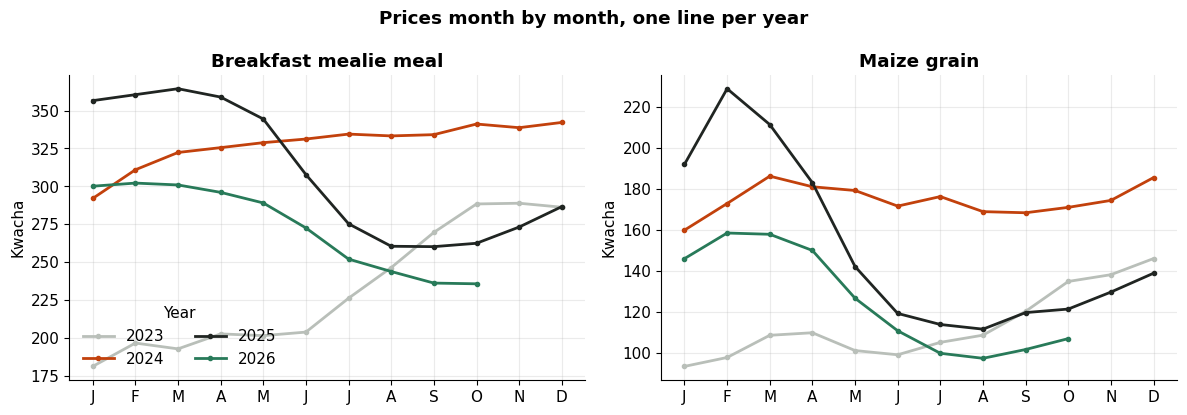

,year,month,price_kwacha
47,2022,2022-12-01,87.75
59,2023,2023-12-01,145.99
62,2024,2024-03-01,186.15
73,2025,2025-02-01,228.76
85,2026,2026-02-01,158.44


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
year_colors = {2023: "#B9BFB9", 2024: "#C2410C", 2025: "#202522", 2026: "#287A59"}
for ax, prod in zip(axes, ["Breakfast mealie meal", "Maize grain"]):
    t = df[df["product"] == prod].copy()
    t["year"], t["m"] = t["month"].dt.year, t["month"].dt.month
    for y, c in year_colors.items():
        ty = t[t["year"] == y]
        ax.plot(ty["m"], ty["price_kwacha"], marker="o", ms=3, lw=2, color=c, label=str(y))
    ax.set_title(prod)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
    ax.set_ylabel("Kwacha")
axes[0].legend(frameon=False, title="Year", loc="lower left", ncol=2)
plt.suptitle("Prices month by month, one line per year", fontweight="bold")
plt.tight_layout()
plt.show()

# In which month did each year's maize grain price peak?
mg = df[df["product"] == "Maize grain"].copy()
mg["year"] = mg["month"].dt.year
mg.loc[mg.groupby("year")["price_kwacha"].idxmax(), ["year", "month", "price_kwacha"]]

**What I see:** In 2025 and 2026, prices followed a clear cycle: they **peaked in February or March**, during the lean season before harvest, then **fell to their lowest around August to October**, after harvest. 2023 and 2024 looked different: prices kept rising almost all year, with no post-harvest drop, which fits a period when supply was under pressure. 2025 (the black line) started from the highest level of any year, then fell the furthest.

*Note: December 2022 is the only month from 2022, so 2022 is not shown as its own line.*

## 5. Where you live matters

ZamStats publishes the cheapest and most expensive district for each product. We have 10 of these snapshots between December 2023 and October 2026.

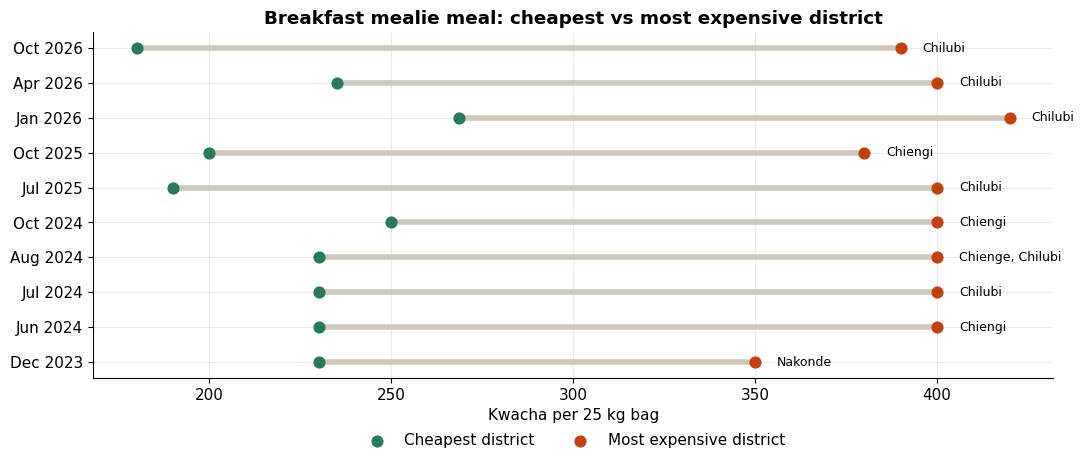

How often each district was the most expensive:
most_expensive_district
Chilubi             5
Chiengi             3
Nakonde             1
Chienge, Chilubi    1
Name: count, dtype: int64

Average gap: the most expensive district paid 1.78 times the cheapest.


In [7]:
p = "Breakfast mealie meal"
d = districts[districts["product"] == p].sort_values("month")
labels = d["month"].dt.strftime("%b %Y")

fig, ax = plt.subplots(figsize=(11, 4.8))
y = range(len(d))
ax.hlines(y, d["min_price_kwacha"], d["max_price_kwacha"], color="#CFC9BB", lw=4)
ax.scatter(d["min_price_kwacha"], y, color="#287A59", s=60, zorder=3, label="Cheapest district")
ax.scatter(d["max_price_kwacha"], y, color="#C2410C", s=60, zorder=3, label="Most expensive district")
for i, (_, r) in enumerate(d.iterrows()):
    ax.text(r["max_price_kwacha"] + 6, i, r["most_expensive_district"], va="center", fontsize=9)
ax.set_yticks(list(y))
ax.set_yticklabels(labels)
ax.set_xlabel("Kwacha per 25 kg bag")
ax.set_title(f"{p}: cheapest vs most expensive district")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

print("How often each district was the most expensive:")
print(d["most_expensive_district"].value_counts())
print("\nAverage gap: the most expensive district paid", round(d["gap_ratio"].mean(), 2), "times the cheapest.")

**What I see:** A few remote districts consistently pay the most. **Chilubi was the most expensive in 5 of the 10 snapshots** and **Chiengi in 3** (they shared the top spot once more). Their price stayed around **K380 to K420** even when the national average fell, so the gap actually grew: in October 2026, a bag cost **2.2 times** more in Chilubi than in the cheapest district, the widest gap in the data. One possible reason is the cost of transporting goods to remote areas, but this data alone can't prove that.

*Note: the minimum price for January 2026 is printed as "268.5.00" in the bulletin. It was read as K268.50 and flagged in the `note` column.*

## 6. Key findings

1. **Prices peaked in early 2025, then fell sharply.** Breakfast mealie meal reached K364 in March 2025 and fell to K236 by October 2026, about 35% lower. Maize grain fell more than 50% from its February 2025 peak.
2. **The hardest time to afford mealie meal came before the price peak.** Adjusted for inflation, breakfast mealie meal was least affordable in April 2024 (K412 in today's money), almost a year before the highest price on the shelf.
3. **Staples are now more affordable than four years ago.** In real terms, all three are cheaper in October 2026 than in December 2022, by about 10% for breakfast mealie meal, 14% for roller mealie meal and 20% for maize grain.
4. **Where you live still matters.** Remote districts such as Chilubi and Chiengi were the most expensive in almost every snapshot, and the gap widened to 2.2 times the cheapest district in October 2026, even as national prices fell.

## 7. Data and limitations

- **Source:** national average retail prices from 10 ZamStats Monthly Bulletins (December 2023 to October 2026 issues), covering every month from December 2022 to October 2026.
- **Checks:** months that appear in more than one bulletin were cross-checked and matched exactly. 18 months rely on a single bulletin (see the `bulletins_confirming` column).
- **Real prices:** calculated by me using ZamStats' all-items Consumer Price Index, expressed in October 2026 Kwacha.
- **National averages:** prices vary a lot between districts, so a national average does not describe every household.
- **District data:** only the cheapest and most expensive district are published, for 10 months, so this is not a full district comparison.
- **What this does not show:** the data shows *when* prices changed, not *why*. Explanations such as the drought or harvest timing are context, not conclusions proven by this data.